# KID Results: Horizontal Bar Chart

Plots Kernel Inception Distance (KID) results from `inception_distance` as a horizontal bar chart.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

In [2]:
# Load the CSV results
results_path = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/data/inception_distance_results/SCAMPER_23/results.csv"
)
df = pd.read_csv(results_path)

# Drop self_comparison, split_baseline, original, and predicted
df = df[
    ~df["dataset"].isin(
        [
            "self_comparison",
            "split_baseline",
            "original_qpos",
            "prior_predicted_logvar_qpos",
        ]
    )
].copy()

# Create clean labels
label_map = {
    "prior_deterministic_qpos": "0.00",
    "prior_logvar_-4_qpos": "0.14",
    "prior_logvar_-3_qpos": "0.22",
    "prior_logvar_-2_qpos": "0.37",
    "prior_logvar_-1_qpos": "0.61",
    "prior_logvar_-0.5_qpos": "0.78",
    "prior_logvar_0_qpos": "1.00",
}
df["label"] = df["dataset"].map(label_map)

# Order by increasing noise
order = list(label_map.values())
df["label"] = pd.Categorical(df["label"], categories=order, ordered=True)
df = df.sort_values("label")

df

,dataset,fid_mean,fid_std,kid_mean,kid_std,label
2,prior_deterministic_qpos,8.254352,0.069215,0.084799,0.003506,0.00
7,prior_logvar_-4_qpos,8.387851,0.181303,0.079734,0.005507,0.14
6,prior_logvar_-3_qpos,8.542082,0.144931,0.084467,0.011978,0.22
5,prior_logvar_-2_qpos,8.685694,0.214123,0.098391,0.008261,0.37
4,prior_logvar_-1_qpos,11.156959,0.323489,0.148056,0.014114,0.61
3,prior_logvar_-0.5_qpos,11.848172,0.303056,0.178383,0.009532,0.78
8,prior_logvar_0_qpos,14.200859,0.424526,0.265873,0.012364,1.00


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/kid_barplot.pdf and .svg


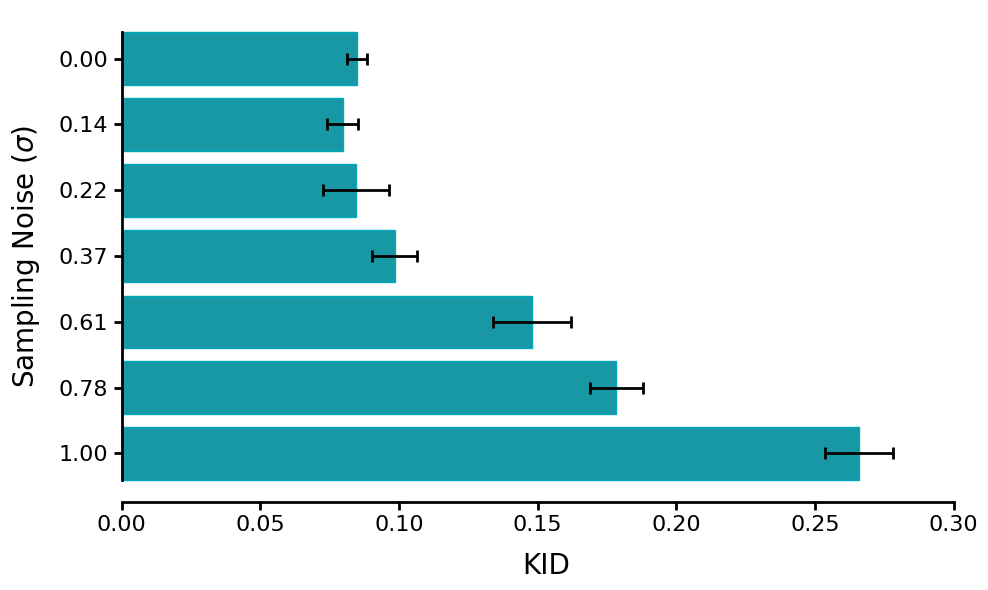

In [3]:
# Set the RGB color for the bars (0-255 scale)
bar_rgb = (0, 170, 188)
bar_color = tuple(c / 255 for c in bar_rgb)

# Save path and filename
save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")
save_name = "kid_barplot"

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=df,
    y="label",
    x="kid_mean",
    color=bar_color,
    edgecolor=bar_color,
    ax=ax,
)

# Get actual bar y-positions from the patches
bar_positions = [patch.get_y() + patch.get_height() / 2 for patch in ax.patches]
bar_positions.sort()

# Add error bars at the correct positions
ax.errorbar(
    df["kid_mean"].values,
    bar_positions,
    xerr=df["kid_std"].values,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# Ensure x-axis covers data + error bars with some padding
x_max = (df["kid_mean"] + df["kid_std"]).max()
ax.set_xlim(0, x_max * 1.1)

ax.set_xlabel("KID", fontsize=20, labelpad=12)
ax.set_ylabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)

# Remove top and right spines
sns.despine(ax=ax)

# Trim bottom spine to tick range (after xlim is set)
xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])

# Trim left spine to bar range
ax.spines["left"].set_bounds(bar_positions[0] - 0.4, bar_positions[-1] + 0.4)

# Thicken the remaining spines
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save as PDF and SVG
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.pdf and .svg")

plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/kid_barplot_vertical.pdf and .svg


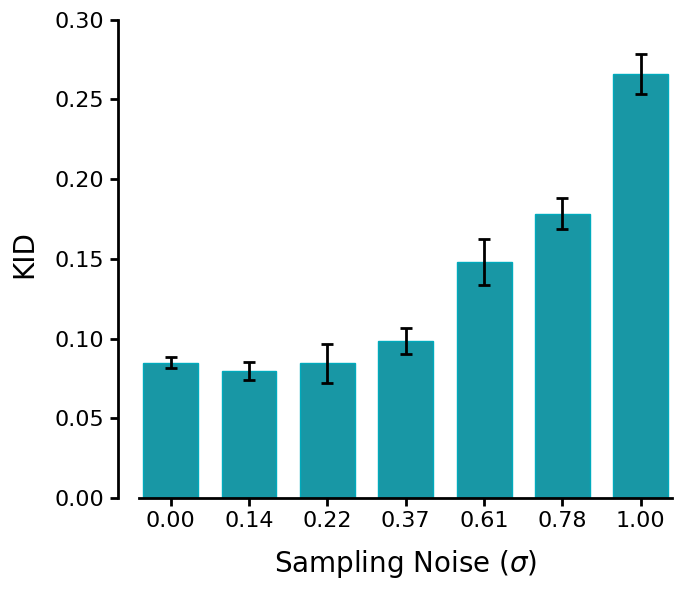

In [4]:
# Vertical bar chart version
save_name_v = "kid_barplot_vertical"

fig, ax = plt.subplots(figsize=(7, 6))

sns.barplot(
    data=df,
    x="label",
    y="kid_mean",
    color=bar_color,
    edgecolor=bar_color,
    width=0.7,
    ax=ax,
)

# Tighten bar spacing by narrowing x-limits
ax.set_xlim(-0.5, len(df) - 0.5)

# Get actual bar x-positions from the patches
bar_positions = [patch.get_x() + patch.get_width() / 2 for patch in ax.patches]
bar_positions.sort()

# Add error bars at the correct positions
ax.errorbar(
    bar_positions,
    df["kid_mean"].values,
    yerr=df["kid_std"].values,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# Ensure y-axis covers data + error bars with some padding
y_max = (df["kid_mean"] + df["kid_std"]).max()
ax.set_ylim(0, y_max * 1.1)

ax.set_ylabel("KID", fontsize=20, labelpad=12)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)

# Remove top and right spines
sns.despine(ax=ax)

# Shift the left spine to the left to create a gap between spines
ax.spines["left"].set_position(("outward", 10))

# Trim left spine to tick range (after ylim is set)
yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])

# Trim bottom spine to bar range
ax.spines["bottom"].set_bounds(bar_positions[0] - 0.4, bar_positions[-1] + 0.4)

# Thicken the remaining spines
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save as PDF, SVG, and PNG
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name_v}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name_v}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name_v}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name_v}.pdf and .svg")

plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/kid_barplot_vertical_comparison.pdf and .svg


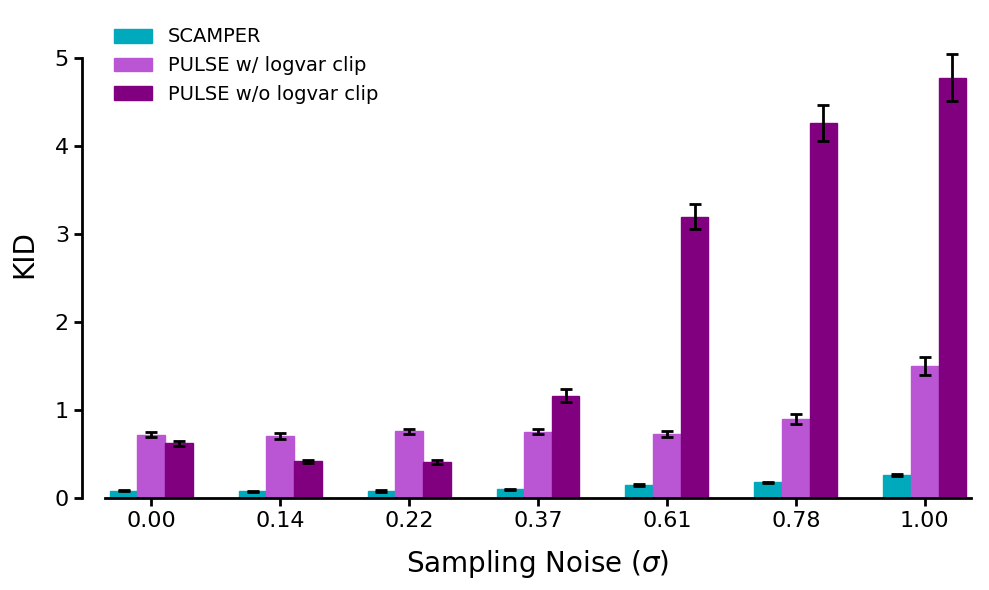

In [6]:
# Grouped vertical bar chart: three result sets side by side
# PULSE w/o logvar clip
results_path_2 = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/data/inception_distance_results/PULSE_49/results.csv"
)
df2 = pd.read_csv(results_path_2)

df2 = df2[
    ~df2["dataset"].isin(
        [
            "self_comparison",
            "split_baseline",
            "original_qpos",
            "prior_predicted_logvar_qpos",
            "teacher_qpos",
        ]
    )
].copy()
df2["label"] = df2["dataset"].map(label_map)
df2["label"] = pd.Categorical(df2["label"], categories=order, ordered=True)
df2 = df2.sort_values("label")

# PULSE w/ logvar clip
results_path_3 = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/data/inception_distance_results/PULSE_clamp_36/results.csv"
)
df3 = pd.read_csv(results_path_3)

df3 = df3[
    ~df3["dataset"].isin(
        [
            "self_comparison",
            "split_baseline",
            "original_qpos",
            "prior_predicted_logvar_qpos",
            "teacher_qpos",
        ]
    )
].copy()
df3["label"] = df3["dataset"].map(label_map)
df3["label"] = pd.Categorical(df3["label"], categories=order, ordered=True)
df3 = df3.sort_values("label")

purple_rgb = (128, 0, 128)
purple_color = tuple(c / 255 for c in purple_rgb)
light_purple_rgb = (186, 85, 211)
light_purple_color = tuple(c / 255 for c in light_purple_rgb)

save_name_cmp = "kid_barplot_vertical_comparison"

fig, ax = plt.subplots(figsize=(10, 6))

n = len(order)
x = np.arange(n) * 1.4
bar_width = 0.3

# SCAMPER bars (left)
ax.bar(
    x - bar_width,
    df["kid_mean"].values,
    bar_width,
    color=bar_color,
    edgecolor=bar_color,
    label="SCAMPER",
)
ax.errorbar(
    x - bar_width,
    df["kid_mean"].values,
    yerr=df["kid_std"].values,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# PULSE w/ logvar clip bars (center)
ax.bar(
    x,
    df3["kid_mean"].values,
    bar_width,
    color=light_purple_color,
    edgecolor=light_purple_color,
    label="PULSE w/ logvar clip",
)
ax.errorbar(
    x,
    df3["kid_mean"].values,
    yerr=df3["kid_std"].values,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# PULSE w/o logvar clip bars (right)
ax.bar(
    x + bar_width,
    df2["kid_mean"].values,
    bar_width,
    color=purple_color,
    edgecolor=purple_color,
    label="PULSE w/o logvar clip",
)
ax.errorbar(
    x + bar_width,
    df2["kid_mean"].values,
    yerr=df2["kid_std"].values,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

ax.set_xticks(x)
ax.set_xticklabels(order)
ax.set_xlim(x[0] - 0.6, x[-1] + 0.6)

# Ensure y-axis covers data + error bars with some padding
y_max = max(
    (df["kid_mean"] + df["kid_std"]).max(),
    (df2["kid_mean"] + df2["kid_std"]).max(),
    (df3["kid_mean"] + df3["kid_std"]).max(),
)
ax.set_ylim(0, y_max * 1.1)

ax.set_ylabel("KID", fontsize=20, labelpad=12)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False, loc="upper left")

# Remove top and right spines
sns.despine(ax=ax)

# Shift the left spine to the left to create a gap between spines
ax.spines["left"].set_position(("outward", 10))

# Trim left spine to tick range (after ylim is set)
yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])

# Trim bottom spine to bar range
ax.spines["bottom"].set_bounds(x[0] - 0.5, x[-1] + 0.5)

# Thicken the remaining spines
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save as PDF, SVG, and PNG
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name_cmp}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name_cmp}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name_cmp}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name_cmp}.pdf and .svg")

plt.show()